# Stage 04 — Statistical Analysis & Hypothesis Testing
Georgia Income Analytics — Gender & Income Study.

Geostat LFS employees, real (2025 GEL) net monthly earnings; periods 2017–2019 and 2020–2025 separate. **Primary** tests are survey-adjusted (weights + household-clustered SE); classical tests are shown for reference. Strata/PSU are not published, so this is an approximation of the full design. Regression and decomposition describe associations, **not causal effects**.

In [1]:
import sys, numpy as np, pandas as pd
from IPython.display import Image, display
sys.path.insert(0,'../src')
pd.set_option('display.width',200,'display.max_colwidth',80,'display.max_columns',30)
R='../reports/'

## 1. Survey design

In [2]:
pd.read_csv(R+'survey_design_summary.csv').T

,0,1
period,2017_2019,2020_2025
n,40141,81166
n_clusters,27824,22200
mean_cluster_size,1.44,3.66
cluster_variable,UID (household within one quarter only),"DiaryID (household, all interviews)"
strata_available,False,False
psu_available,False,False
weight_cv,0.796,0.79
kish_deff_weights,1.633,1.624
effective_n_weights,24577,49969


## 2. Hypotheses and tests (BH-adjusted p-values)

In [3]:
h = pd.read_csv(R+'hypothesis_results.csv')
h[['period','hypothesis','H0','test','statistic','p_value','p_value_bh','estimate','ci_low','ci_high','estimate_meaning']]

,period,hypothesis,H0,test,statistic,p_value,p_value_bh,estimate,ci_low,ci_high,estimate_meaning
0,2017_2019,H1,Mean earnings of women and men are equal,"Welch t-test (classical, unweighted)",4.622993e+01,0.000000e+00,0.000000e+00,253.260435,242.522860,263.998011,men minus women
1,2017_2019,H1,Mean earnings of women and men are equal,"Weighted regression, household-clustered SE (survey-adjusted, PRIMARY)",-2.955629e+01,5.451681e-192,1.319307e-191,265.720499,248.099797,283.341201,men minus women
2,2017_2019,H1,Mean earnings of women and men are equal,"Welch t-test (classical, unweighted)",5.156600e+01,0.000000e+00,0.000000e+00,0.351687,0.338319,0.365054,men minus women
3,2017_2019,H1,Mean earnings of women and men are equal,"Weighted regression, household-clustered SE (survey-adjusted, PRIMARY)",-4.041123e+01,0.000000e+00,0.000000e+00,0.345902,0.329125,0.362678,men minus women
4,2017_2019,H1,Mean earnings of women and men are equal,"Mann-Whitney U (classical, unweighted)",2.640732e+08,0.000000e+00,0.000000e+00,0.311113,NaN,NaN,rank-biserial r = P(man > woman) - P(woman > man)
5,2017_2019,H2,No gender gap after controlling for age,Weighted regression log earnings ~ female + age group (clustered SE),-3.940220e+01,0.000000e+00,0.000000e+00,28.487379,27.284656,29.670209,% women earn less than men with the same age group (1 - exp(b))
6,2017_2019,H3,No gender gap after controlling for education,Weighted regression log earnings ~ female + education (clustered SE),-4.874719e+01,0.000000e+00,0.000000e+00,33.750377,32.644504,34.838094,% women earn less than men with the same education (1 - exp(b))
7,2017_2019,H4,No gender gap within the same occupation group,Weighted regression log earnings ~ female + occupation (ISCO major group) (c...,-4.185539e+01,0.000000e+00,0.000000e+00,31.487547,30.263532,32.690078,% women earn less than men with the same occupation (ISCO major group) (1 - ...
8,2017_2019,H5,Mean earnings do not differ between regions,One-way ANOVA by region (classical),2.124390e+02,0.000000e+00,0.000000e+00,0.045476,NaN,NaN,eta-squared
9,2017_2019,H5,Mean earnings do not differ between regions,Welch ANOVA by region (classical),2.125680e+02,0.000000e+00,0.000000e+00,0.045476,NaN,NaN,eta-squared


## 3. Gender pay gap with 95% CI

In [4]:
pd.read_csv(R+'gap_confidence_intervals.csv')

,period,measure,estimate,ci_low,ci_high,se,method
0,2017_2019,mean gap %,27.880679,26.382698,29.292857,0.764902,cluster Poisson bootstrap B=1000
1,2017_2019,mean gap % (delta method check),27.880679,26.338324,29.423034,0.786916,"delta method, weighted regression, clustered SE"
2,2017_2019,median gap %,31.791228,30.668381,32.857154,0.597496,cluster Poisson bootstrap B=200; quantiles interpolated within bands
3,2017_2019,hourly median gap %,17.050375,15.483766,18.406751,0.836938,cluster Poisson bootstrap B=200; quantiles interpolated within bands
4,2017_2019,mean gap % 2017,30.075097,26.861605,33.099474,1.593459,cluster Poisson bootstrap B=1000
5,2017_2019,mean gap % 2018,26.269652,23.549669,28.554927,1.283208,cluster Poisson bootstrap B=1000
6,2017_2019,mean gap % 2019,27.311938,25.050424,29.508295,1.125569,cluster Poisson bootstrap B=1000
7,2020_2025,mean gap %,25.471020,24.183252,26.723275,0.649878,cluster Poisson bootstrap B=1000
8,2020_2025,mean gap % (delta method check),25.471020,24.160716,26.781325,0.668523,"delta method, weighted regression, clustered SE"
9,2020_2025,median gap %,28.781875,27.403003,29.829031,0.632717,cluster Poisson bootstrap B=200; quantiles interpolated within bands


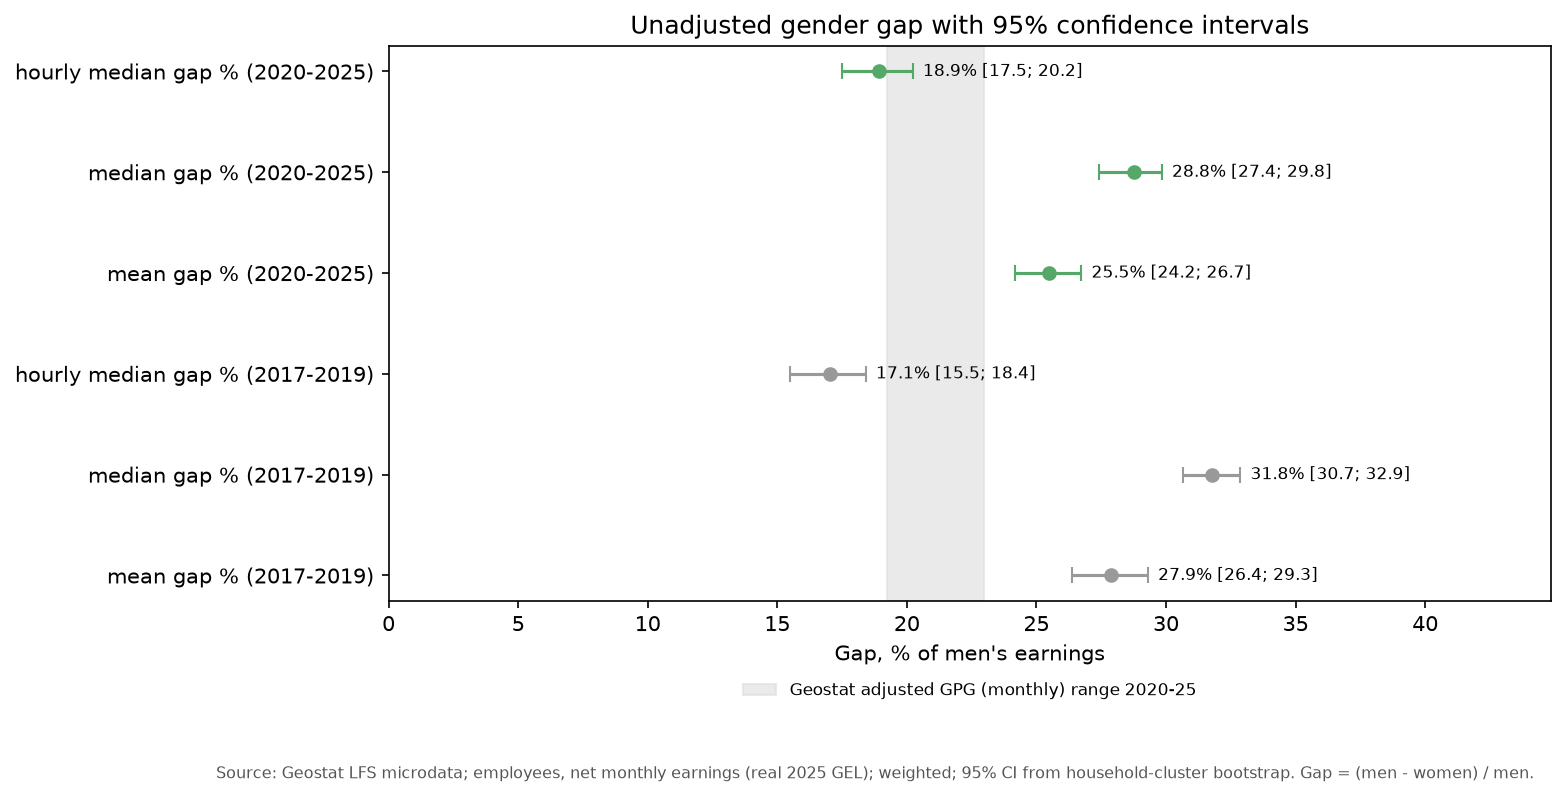

In [5]:
display(Image('../reports/figures/stage_04/01_confidence_interval_comparison.png'))

## 4. Gaps by subgroup

In [6]:
pd.read_csv(R+'subgroup_gaps.csv')[['period','dimension','group','n_female','n_male','reliability','gap_mean_pct','ci_low','ci_high','p_value_bh']]

,period,dimension,group,n_female,n_male,reliability,gap_mean_pct,ci_low,ci_high,p_value_bh
0,2017_2019,age,15-17,30,48,low_n,-81.651932,-287.092758,43.592041,7.144835e-01
1,2017_2019,age,18-24,1157,1869,ok,25.492224,20.530102,29.595121,4.633204e-14
2,2017_2019,age,25-34,4127,5284,ok,25.211105,22.602266,27.837469,6.571627e-87
3,2017_2019,age,35-44,4699,4290,ok,33.874622,29.933848,37.113670,2.346058e-136
4,2017_2019,age,45-54,4721,3992,ok,24.762819,21.671165,28.159588,9.560566e-71
...,...,...,...,...,...,...,...,...,...,...
64,2020_2025,occupation,Plant & machine operators,725,5859,ok,37.061293,31.086440,41.931408,8.911373e-39
65,2020_2025,occupation,Professionals,13393,4042,ok,24.710172,21.715713,28.093078,1.046097e-45
66,2020_2025,occupation,Service & sales,7952,7219,ok,15.573070,12.748523,18.559083,4.737689e-11
67,2020_2025,occupation,Skilled agricultural,87,309,low_n,11.304160,-6.824821,30.069609,1.178364e-01


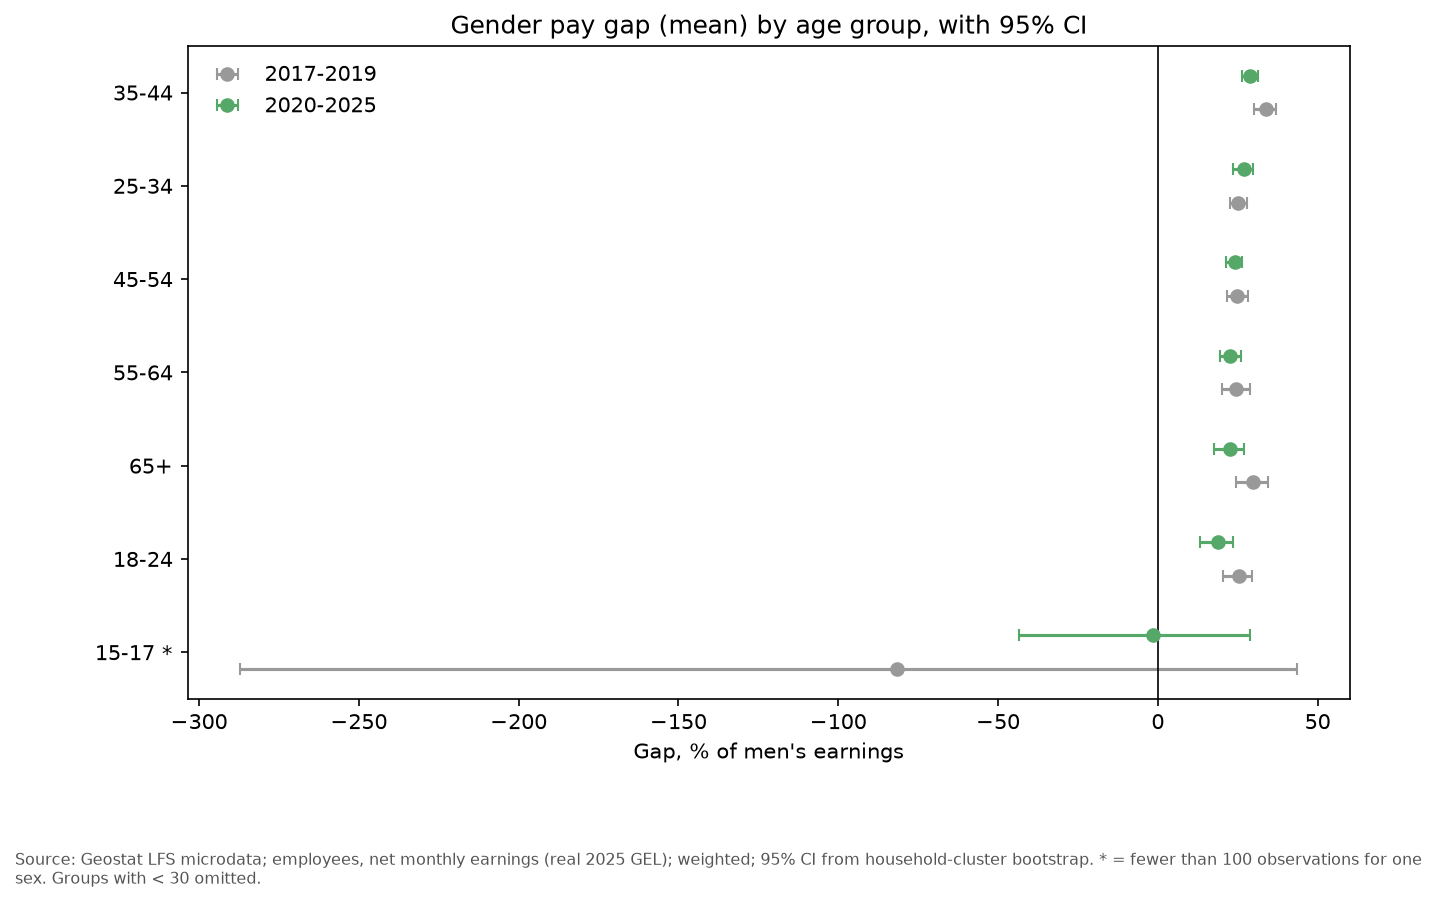

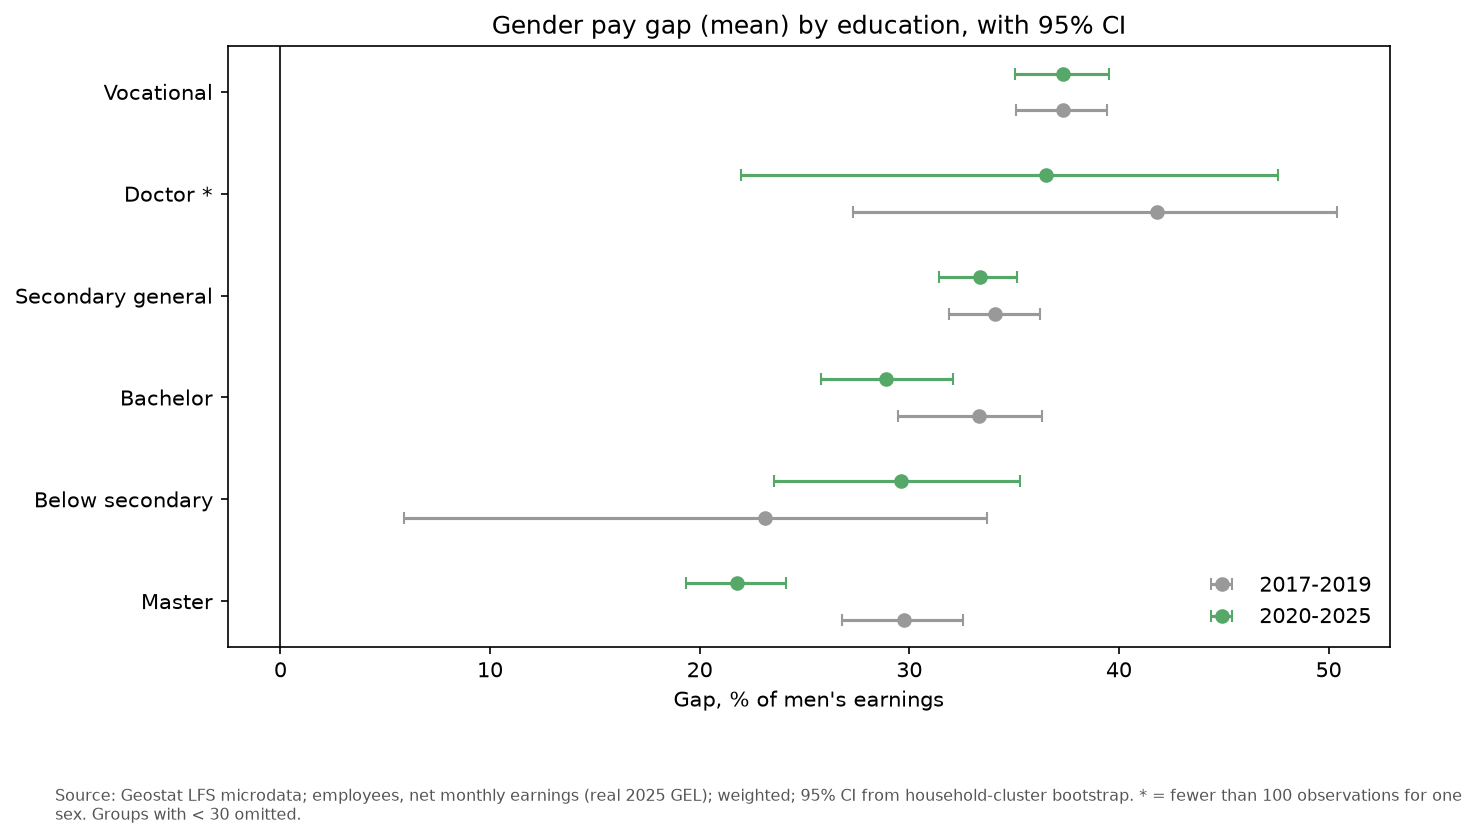

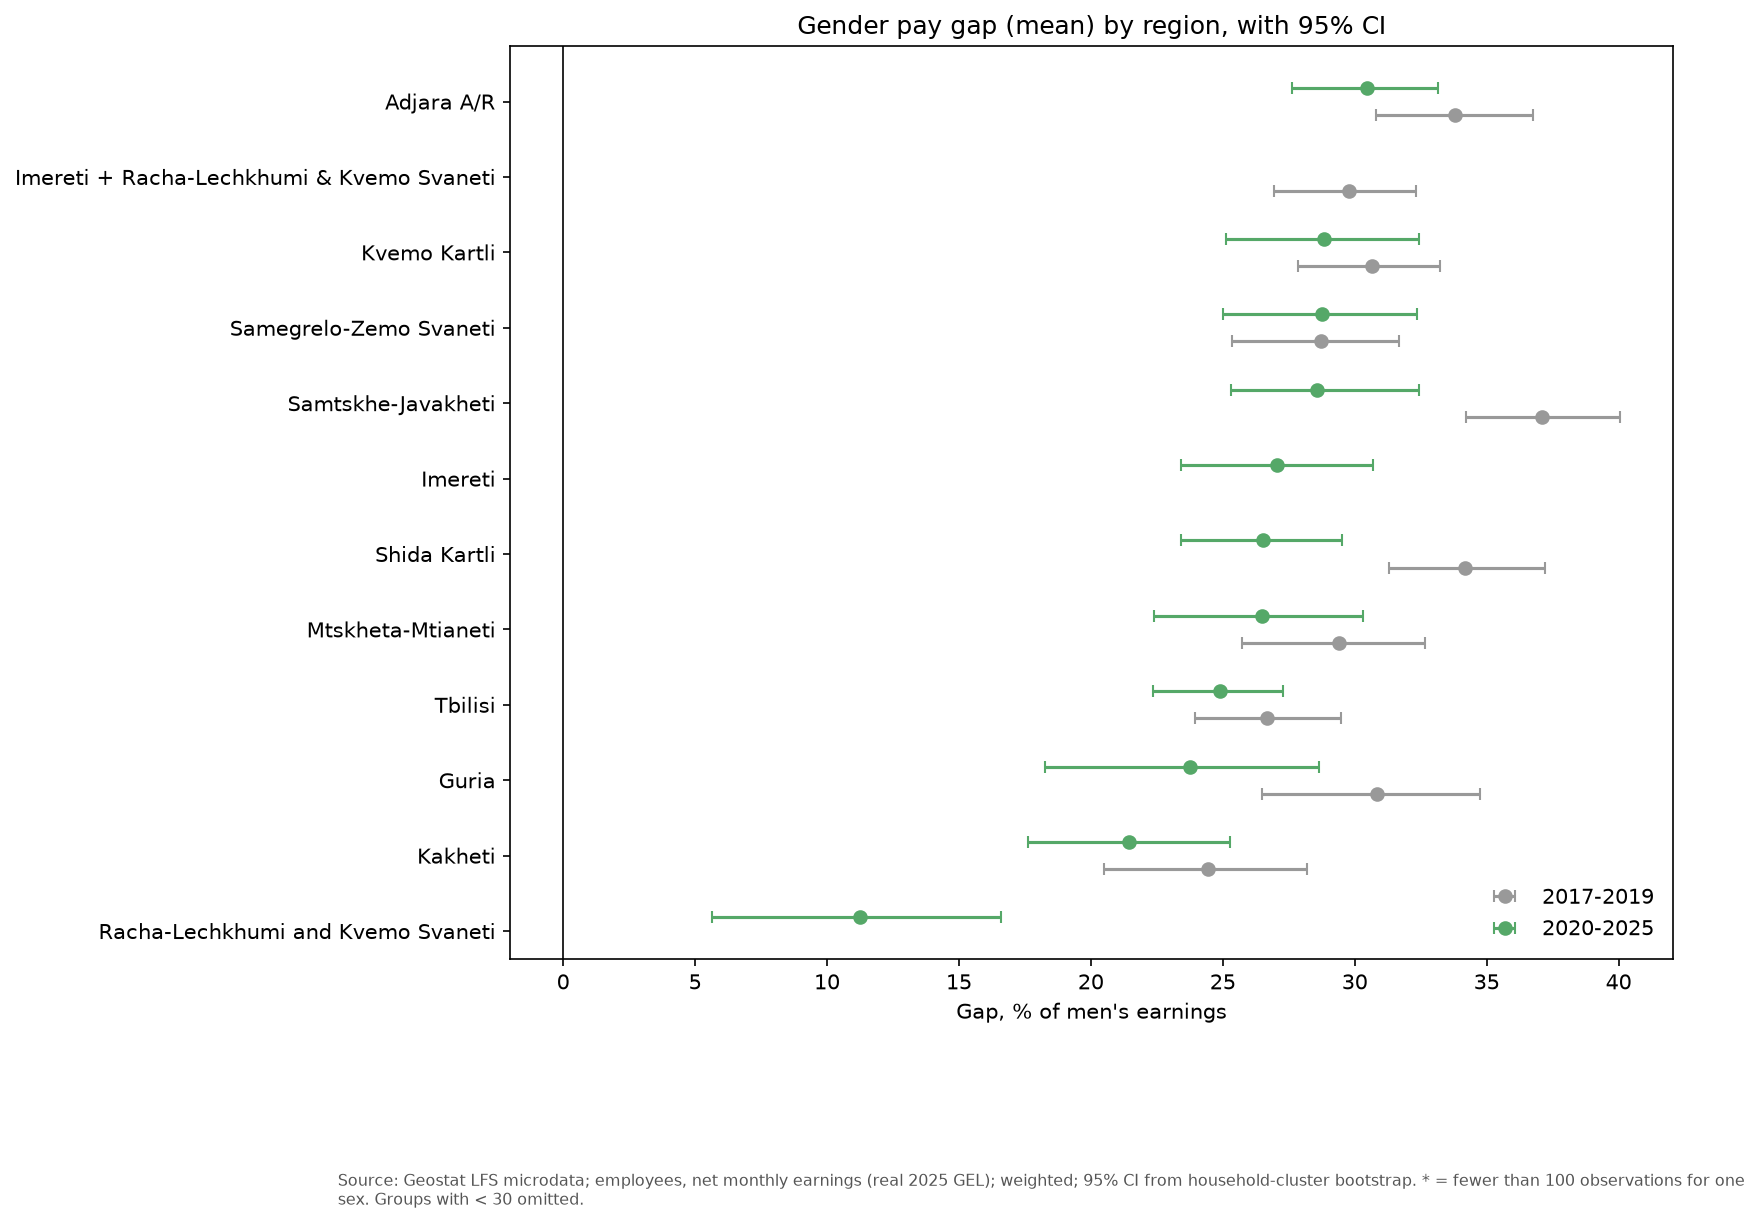

In [7]:
for f in ['02_gender_pay_gap_by_age','03_gender_pay_gap_by_education','04_gender_pay_gap_by_region']:
    display(Image('../reports/figures/stage_04/'+f+'.png'))

## 5. Effect sizes

,period,comparison,scale,measure,value,ci_low,ci_high,magnitude
0,2017_2019,men vs women,level GEL,Cohen's d (unweighted),0.461749,NaN,NaN,small
1,2017_2019,men vs women,level GEL,Cohen's d (weighted),0.435490,NaN,NaN,small
2,2017_2019,men vs women,level GEL,Hedges' g (unweighted),0.461740,0.441915,0.481565,small
3,2017_2019,men vs women,log,Cohen's d (unweighted),0.514746,NaN,NaN,medium
4,2017_2019,men vs women,log,Cohen's d (weighted),0.506661,NaN,NaN,medium
5,2017_2019,men vs women,log,Hedges' g (unweighted),0.514736,0.494849,0.534623,medium
6,2017_2019,men vs women,rank,rank-biserial r,0.311113,NaN,NaN,medium
7,2017_2019,between region groups,log,eta-squared,0.045476,NaN,NaN,small
8,2017_2019,between region groups,log,epsilon-squared (KW),0.043777,NaN,NaN,small
9,2017_2019,between age group groups,log,eta-squared,0.028110,NaN,NaN,small


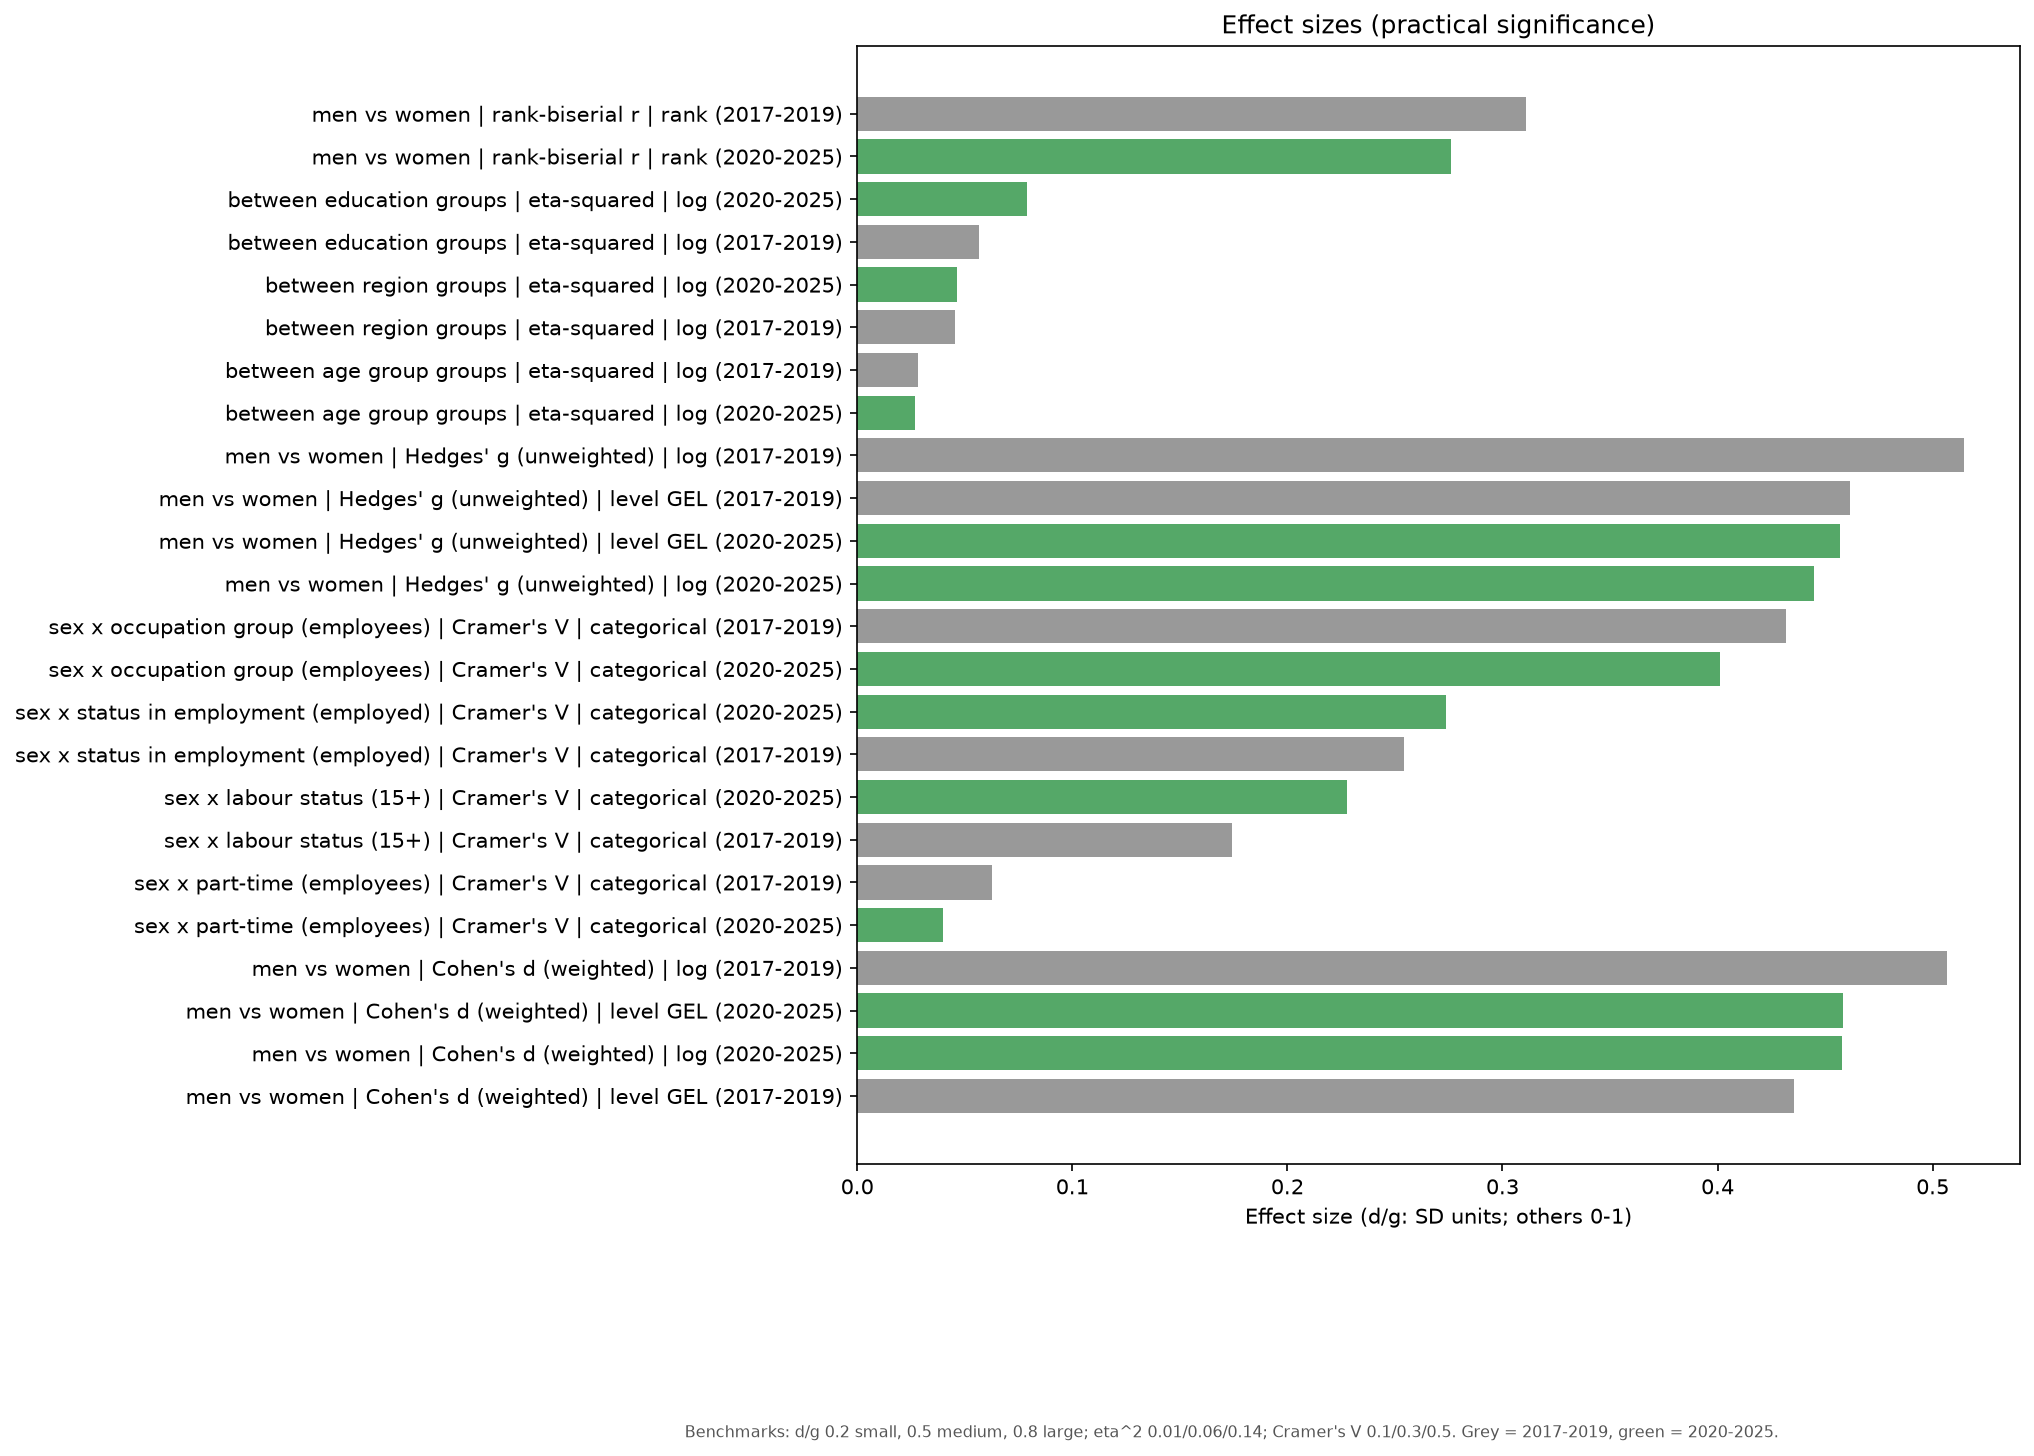

In [8]:
display(pd.read_csv(R+'effect_sizes.csv'))
display(Image('../reports/figures/stage_04/06_effect_size_comparison.png'))

## 6. Regression: female coefficient as % (exp(b)-1)

In [9]:
r = pd.read_csv(R+'regression_results.csv')
r[r.term=='female'][['period','model','coef','pct_effect','pct_ci_low','pct_ci_high','p_value','n','r2','adj_r2']]

,period,model,coef,pct_effect,pct_ci_low,pct_ci_high,p_value,n,r2,adj_r2
1,2017_2019,M1 gender only,-0.344862,-29.168179,-30.379609,-27.935671,0.000000e+00,37480,0.061508,0.061483
3,2017_2019,M2 + experience,-0.333691,-28.372514,-29.570773,-27.153869,0.000000e+00,37480,0.104523,0.104451
13,2017_2019,M3 + education,-0.398732,-32.882970,-33.992204,-31.755096,0.000000e+00,37480,0.178674,0.178477
32,2017_2019,M4 + occupation,-0.355601,-29.924812,-31.147005,-28.680925,0.000000e+00,37480,0.230452,0.230082
61,2017_2019,M5 + region,-0.360416,-30.261409,-31.450119,-29.052087,0.000000e+00,37480,0.273243,0.272699
90,2017_2019,M6 + hours,-0.304621,-26.259715,-27.494910,-25.003479,1.244226e-273,37480,0.347639,0.347116
147,2017_2019,M7 full,-0.217778,-19.569602,-21.010724,-18.102188,3.180448e-123,37480,0.411285,0.410373
155,2017_2019,L1 simple linear (GEL),-266.008267,NaN,NaN,NaN,1.394076e-173,37480,0.045783,0.045758
208,2017_2019,L7 multiple linear (GEL),-188.157955,NaN,NaN,NaN,1.588574e-69,37480,0.311179,0.310111
267,2017_2019,H7 log hourly earnings (hours>=10),-0.162764,-15.020852,-16.616738,-13.394422,1.546651e-63,36964,0.354442,0.353463


In [10]:
display(pd.read_csv(R+'vif_results.csv'))
display(pd.read_csv(R+'regression_diagnostics.csv'))

,period,term,df,gvif,gvif_adj
0,2017_2019,C(education_eda),6,2.737330,1.087537
1,2017_2019,C(occupation_label),9,8.634371,1.127231
2,2017_2019,C(region_eda),9,1.580315,1.025750
3,2017_2019,C(urban_rural),1,1.337116,1.156337
4,2017_2019,C(industry_label),20,41.977205,1.097932
5,2017_2019,C(sector_cat),3,5.056555,1.310114
6,2017_2019,C(contract),1,1.836891,1.355320
7,2017_2019,C(year_cat),2,2.969738,1.312743
8,2017_2019,female,1,1.552254,1.245895
9,2017_2019,exp,1,1.569868,1.252944


,period,model,outcome,n,r2,adj_r2,female_coef,female_pct,female_p,converged,sigma,bp_lm,bp_p,note
0,2017_2019,M1 gender only,log real earnings,37480,0.061508,0.061483,-0.344862,-29.168179,0.000000e+00,NaN,NaN,NaN,NaN,NaN
1,2017_2019,M2 + experience,log real earnings,37480,0.104523,0.104451,-0.333691,-28.372514,0.000000e+00,NaN,NaN,NaN,NaN,NaN
2,2017_2019,M3 + education,log real earnings,37480,0.178674,0.178477,-0.398732,-32.882970,0.000000e+00,NaN,NaN,NaN,NaN,NaN
3,2017_2019,M4 + occupation,log real earnings,37480,0.230452,0.230082,-0.355601,-29.924812,0.000000e+00,NaN,NaN,NaN,NaN,NaN
4,2017_2019,M5 + region,log real earnings,37480,0.273243,0.272699,-0.360416,-30.261409,0.000000e+00,NaN,NaN,NaN,NaN,NaN
5,2017_2019,M6 + hours,log real earnings,37480,0.347639,0.347116,-0.304621,-26.259715,1.244226e-273,NaN,NaN,NaN,NaN,NaN
6,2017_2019,M7 full,log real earnings,37480,0.411285,0.410373,-0.217778,-19.569602,3.180448e-123,NaN,NaN,NaN,NaN,NaN
7,2017_2019,L1 simple linear (GEL),real earnings GEL,37480,0.045783,0.045758,-266.008267,-27.789906,1.394076e-173,NaN,NaN,NaN,NaN,NaN
8,2017_2019,L7 multiple linear (GEL),real earnings GEL,37480,0.311179,0.310111,-188.157955,NaN,1.588574e-69,NaN,NaN,NaN,NaN,NaN
9,2017_2019,H7 log hourly earnings (hours>=10),log real hourly earnings,36964,0.354442,0.353463,-0.162764,-15.020852,1.546651e-63,NaN,NaN,NaN,NaN,NaN


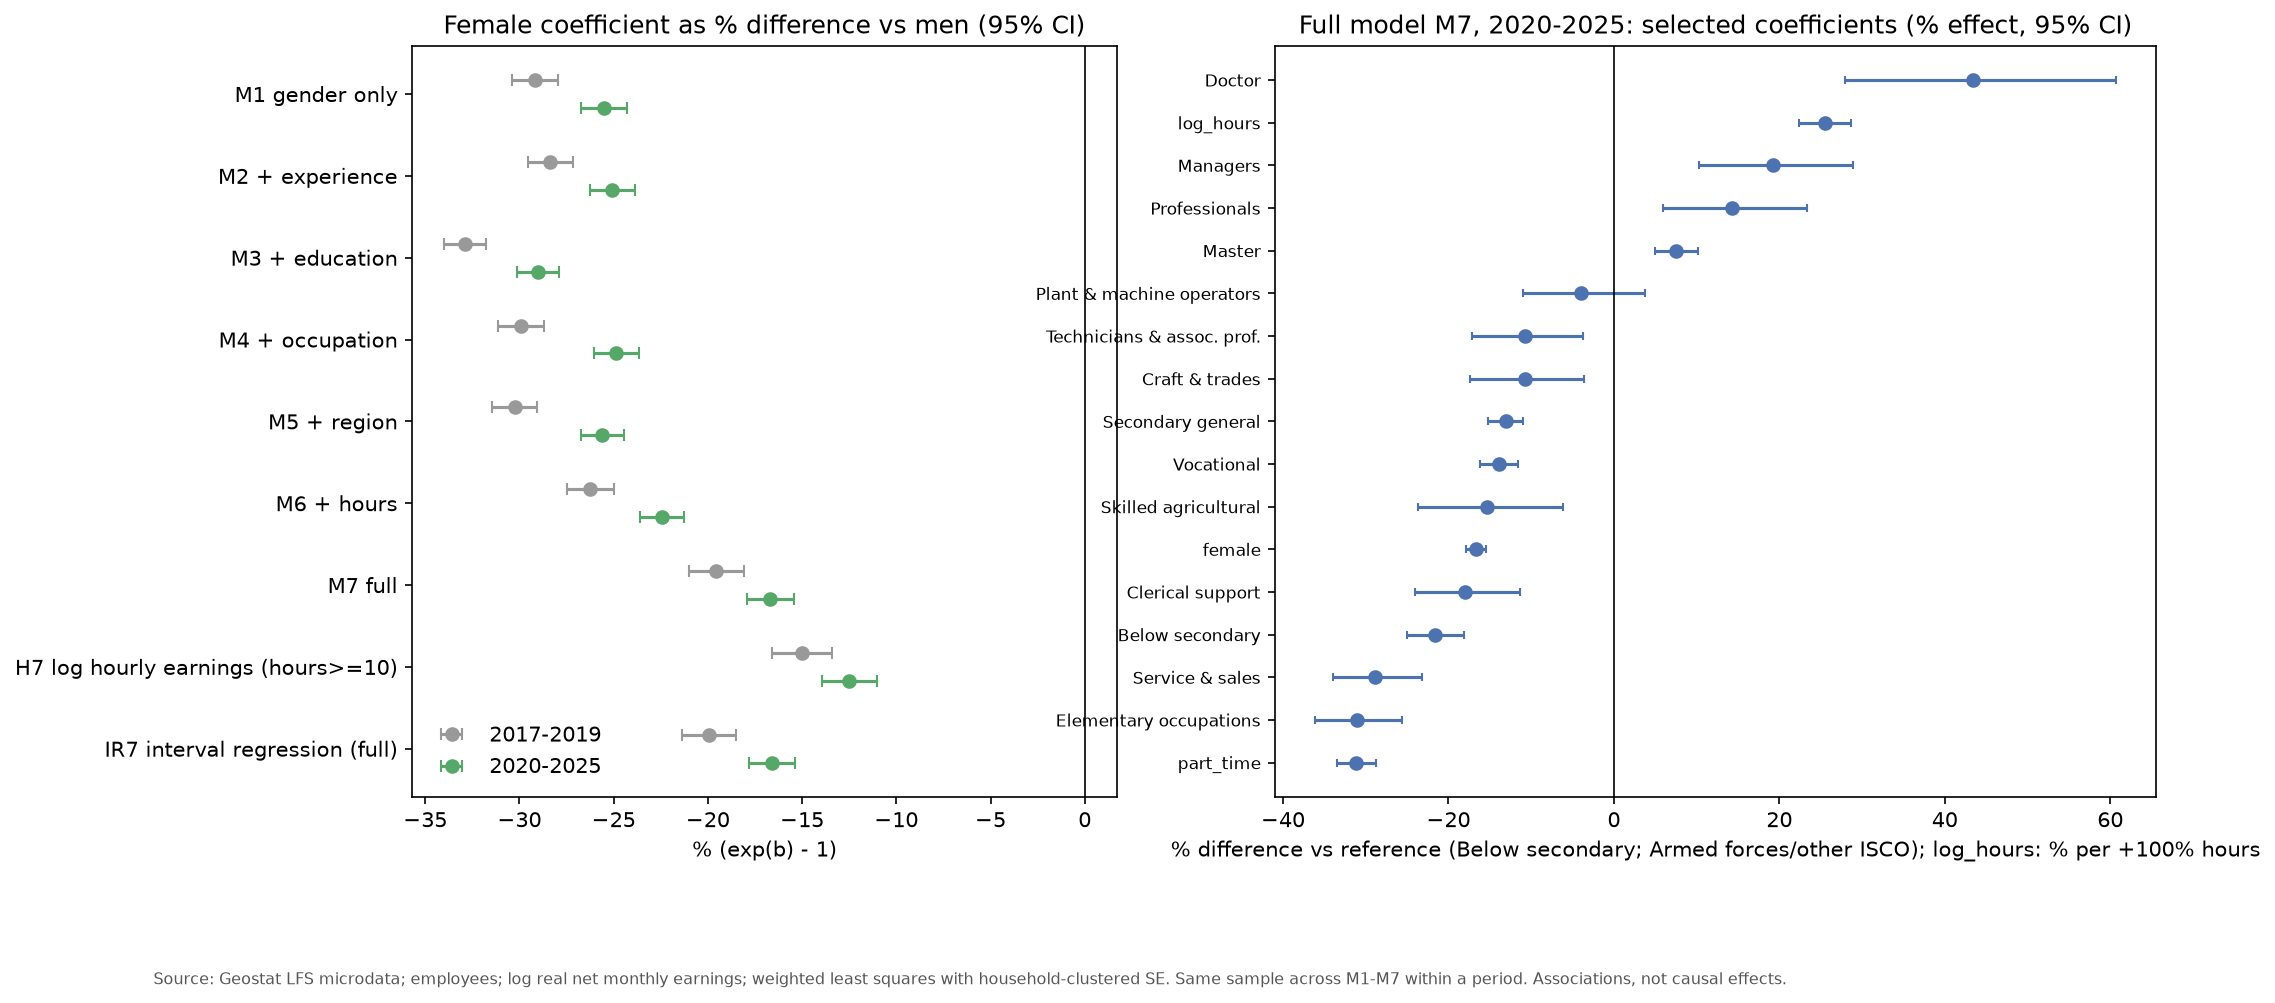

In [11]:
display(Image('../reports/figures/stage_04/05_regression_coefficient_plot.png'))

## 7. Oaxaca–Blinder decomposition

,period,component,reference,log_points,ci_low,ci_high,se,share_of_gap_pct,pct_equivalent
0,2017_2019,gap,pooled (Neumark),0.344862,0.327674,0.360039,0.008579,100.000000,41.179486
1,2017_2019,explained,pooled (Neumark),0.127084,0.113663,0.139980,0.007313,36.850655,13.551222
2,2017_2019,unexplained,pooled (Neumark),0.217778,0.200919,0.234098,0.008987,63.149345,24.331102
3,2017_2019,explained: education,pooled (Neumark),-0.028661,-0.032682,-0.023656,0.002394,-8.310964,NaN
4,2017_2019,explained: occupation,pooled (Neumark),-0.044631,-0.054531,-0.036054,0.004901,-12.941810,NaN
5,2017_2019,explained: region & urban,pooled (Neumark),-0.006628,-0.009884,-0.003322,0.001652,-1.921847,NaN
6,2017_2019,explained: industry,pooled (Neumark),0.138124,0.128089,0.147410,0.005221,40.051873,NaN
7,2017_2019,"explained: job type (sector, informality, contract)",pooled (Neumark),-0.007920,-0.011563,-0.003901,0.001976,-2.296485,NaN
8,2017_2019,explained: survey year,pooled (Neumark),-0.000421,-0.000820,-0.000033,0.000225,-0.122127,NaN
9,2017_2019,explained: experience,pooled (Neumark),0.005217,0.002925,0.007376,0.001162,1.512659,NaN


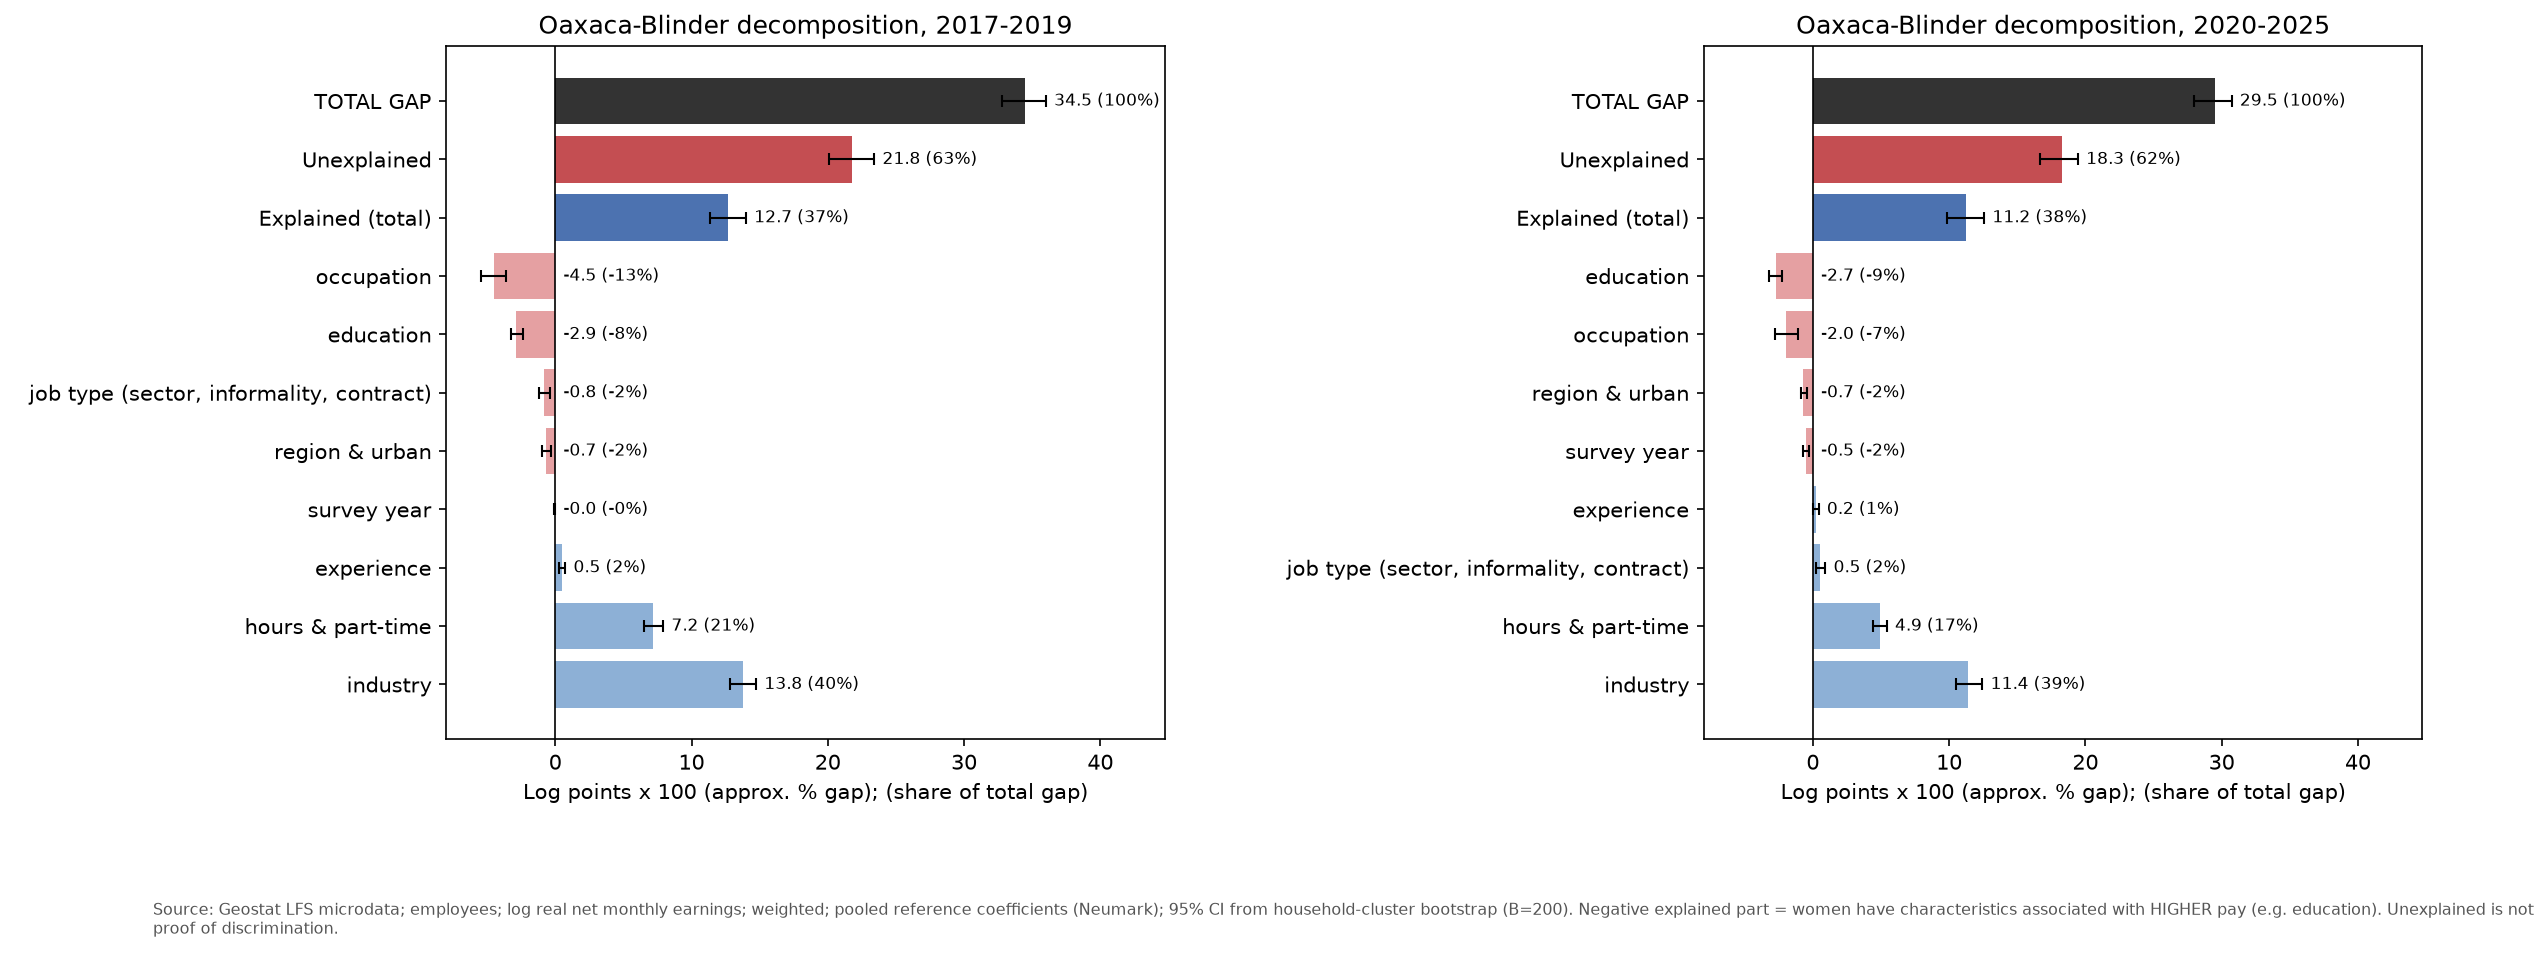

In [12]:
display(pd.read_csv(R+'oaxaca_results.csv'))
display(Image('../reports/figures/stage_04/07_oaxaca_blinder_decomposition.png'))

## 8. Independent re-check of headline numbers

In [13]:
import survey_analysis as sa, regression_analysis as ra
d = sa.load_period('2020_2025')
f, m = d[d.female==1], d[d.female==0]
wm, wf = np.average(m.y, weights=m.w), np.average(f.y, weights=f.w)
print('weighted mean gap % (recomputed):', round((wm-wf)/wm*100, 2))
s = ra.estimation_sample(d)
b = sa.wls_cluster('log_y ~ female', s).params['female']
print('M1 log gap -> % :', round((np.exp(b)-1)*100, 2))

weighted mean gap % (recomputed): 25.47
M1 log gap -> % : -25.54
